<a href="https://colab.research.google.com/github/Bootcamp-DA-P3/M-nimos_Cuadrados_Parciales_DR/blob/main/Equipo5_PLS_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🕵️‍♂️ Equipo 5: Mínimos Cuadrados Parciales (PLS Regression)
**Taller de investigación de algoritmos de regresión**

---
## Índice del Notebook
1. **¿Qué es PLS y qué problema resuelve?**
2. **Fundamento Matemático e Hiperparámetros**
3. **Casos de Uso e Importancia en la Industria**
4. **Implementación Práctica en Python** (Demostración y gráficos)
5. **Conclusiones: Ventajas y Limitaciones**

## 1. Qué es y para qué sirve
La regresión PLS ajusta un modelo lineal Y=XB+E reduciendo primero los predictores a unos pocos componentes no correlacionados y haciendo mínimos cuadrados sobre ellos. Y es la matriz de respuestas (n × m), X la de predictores (n × p), B la de coeficientes y E es la matriz de los errores.
Es especialmente útil cuando:
- Los predictores están muy correlacionados (colinealidad) o hay más predictores que observaciones, situaciones en las que MCO da coeficientes con errores estándar enormes o directamente falla (Minitab).
- Se busca un modelo predictivo más que explicativo. No suele usarse para descartar variables poco útiles.
- Hay varias respuestas a la vez: PLS puede ajustarlas en un único modelo, y los resultados pueden diferir bastante de ajustar cada una por separado.





La regresión PLS sirve para hacer predicciones seguras y estables cuando tus datos están amontonados, repetidos o enredados, logrando adivinar varios resultados a la vez al concentrarse en la puntería del modelo en lugar de perder tiempo explicando cada detalle.

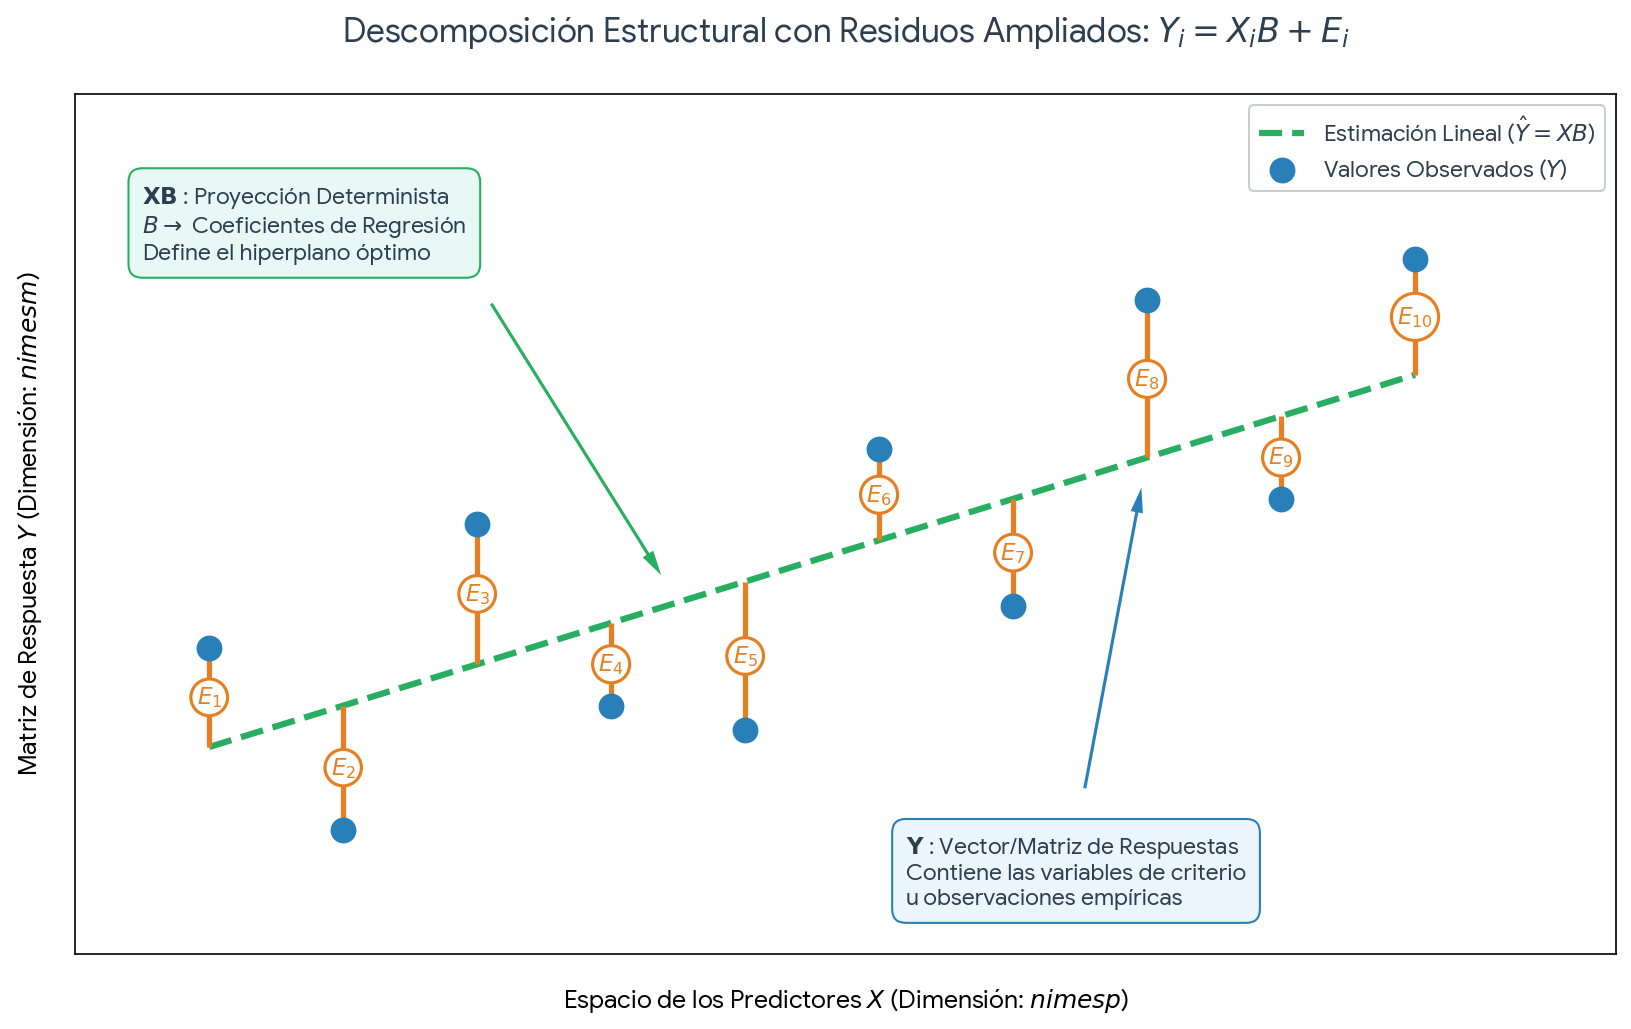

## 2. Fundamento matemático e hiperparámetros
PLS elige cada componente maximizando la covarianza entre predictores y respuesta, no la varianza de los predictores. Concretamente, busca vectores de pesos w y c que maximizan la covarianza al cuadrado entre las puntuaciones Xw e Yc (Rosipal y Krämer):

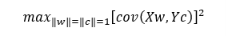


### 2.1 Modelo de factores
PLS descompone X e Y en puntuaciones (T, U) y cargas (P, Q), como documenta scikit-learn:

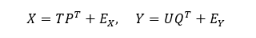

Tras elegir A componentes, los coeficientes en términos de las variables originales son (con T=XR) (Mevik y Wehrens):

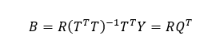

### 2.2 Hiperparámetro
• Definición: Determina la cantidad exacta de variables latentes (componentes) que el modelo va a extraer de los datos.

• Bajo valor (Subajuste): El modelo pierde patrones importantes de información y el error de predicción es alto.

• Alto valor (Sobreajuste): El modelo memoriza el ruido aleatorio del conjunto de entrenamiento y falla estrepitosamente con datos nuevos.

• Calibración óptima: Se selecciona mediante Validación Cruzada, eligiendo el punto donde el error de validación (RMSECV) alcanza su valor mínimo.

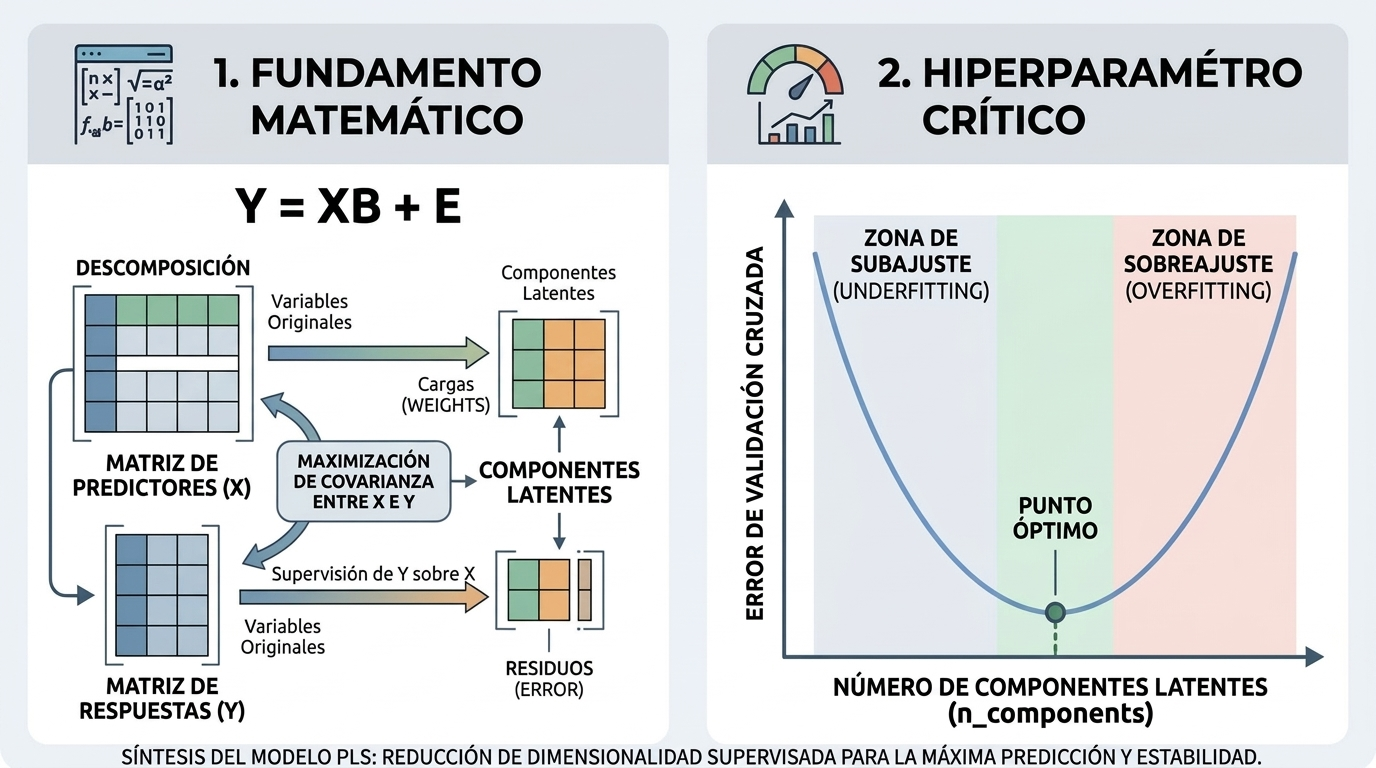

# Algoritmos

###Hay dos algoritmos principales: NIPALS, que extrae un factor cada vez y deflacta los datos, y SIMPLS, que evita deflactar X e Y.

##NIPALS (el clásico)

Parte de X_0 e Y_0 centradas y escaladas, calcula t=X_0 w y predice X_0 e Y_0 por regresión sobre t. Luego deflacta (resta lo explicado) y repite (JMP).
Para una sola respuesta (PLS1), el esquema habitual es el siguiente (conocimiento general, no extraído de una fuente concreta):

Centrar X e y y, normalmente, escalar X.

Para a=1,…,A:

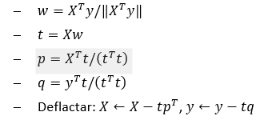

Con los A componentes, calcular los coeficientes:

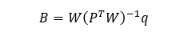

##SIMPLS (de Jong, 1993)

Calcula los factores PLS directamente como combinaciones lineales de las variables originales, maximizando la covarianza bajo restricciones de ortogonalidad y normalización, y sin construir las matrices deflactadas de NIPALS. En su lugar deflacta la matriz de productos cruzados X_0'Y_0.

  -Con una única Y, SIMPLS equivale a PLS1; con Y multivariante hay una pequeña diferencia respecto a NIPALS-PLS2.

  -Según la documentación del paquete pls, SIMPLS maximiza de verdad el criterio de covarianza y, según de Jong, queda más cerca de PCR (predicciones estables), mientras que los PLS2 estándar quedan más cerca de MCO (ajuste preciso) (pls, simpls.fit).
  
  -Es más rápido que NIPALS, sobre todo cuando crece el número de variables X.


# 3. Casos de Uso e Importancia en la Industria

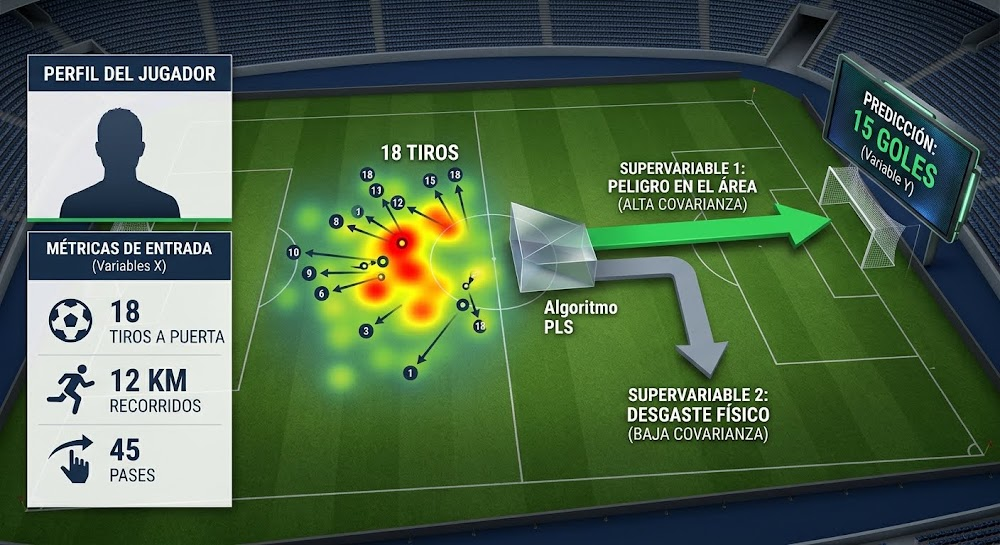

• ¿Qué es? Es un método estadístico que limpia el ruido del Big Data y predice un resultado exacto cuando hay métricas repetidas o hiperconectadas (multicolinealidad), como cuando un jugador tiene muchos pases y kilómetros solo por jugar más minutos.

• Métricas de Entrada (Variables X): Son los datos crudos del recuadro izquierdo (18 tiros, 12 km, 45 pases), junto con la geografía de la cancha: el mapa de calor (dónde se mueve) y el mapa de tiros (las flechas desde dónde chuta).

• El Algoritmo PLS (El Prisma Central): Analiza al mismo tiempo los datos (X) y los goles (Y). Funciona como un prisma que separa la luz; calcula la máxima covarianza para dividir la información en dos bloques según su utilidad real para marcar:

1. Supervariable 1 - Flecha Verde (Alta Covarianza): Junta la mancha roja del mapa de calor y los 18 tiros cerca del arco (Peligro en el Área). Al ver que esta combinación se mueve al mismo ritmo que el marcador, el modelo le da prioridad máxima y apunta directo a la red.
2. Supervariable 2 - Flecha Gris (Baja Covarianza): Junta los 12 km recorridos y los pases en zonas inútiles (Desgaste Físico). El algoritmo detecta matemáticamente que correr mucho no garantiza el gol, por lo que desvía este bloque y lo ignora para no estropear los cálculos.
  
• Predicción: 15 Goles (Variable Y): Es la pantalla final del estadio. El algoritmo digiere el océano de números cruzados y te entrega una predicción objetiva y limpia de goles para decidir el fichaje.


Frente a cualquier otra herramienta estadística o de Machine Learning, el PLS se elige por tres razones críticas diseñadas para tu presentación:

🎯 1. Domina el Big Data Redundante

• El Reto: Los datos masivos suelen estar duplicados, hiperconectados y estorbarse entre sí (multicolinealidad).
• La Solución: Es el único método diseñado matemáticamente para estabilizar y digerir este caos sin perder información valiosa en el camino.

⏱️ 2. Predicción Instantánea (Tiempo Real)

• La Analogía: En la industria, el campo de juego es la planta de producción y el gol es la pureza perfecta del producto.
• El Beneficio: El algoritmo lee el "mapa de calor" de los sensores químicos y calcula la calidad en un milisegundo. Evita por completo tener que congelar la fábrica durante 4 horas para enviar muestras físicas a un laboratorio tradicional.

💰 3. Evita tirar Dinero a la Basura (Ahorro Millonario)

• La Analogía: En el fútbol, el algoritmo evita que gastes millones fichando al jugador equivocado por culpa de mirar datos de relleno que se van a la flecha gris.
• El Beneficio: En la fábrica, si el proceso químico empieza a desviarse de la flecha verde, los ingenieros lo ven al instante en el monitor táctico. Pueden corregir los parámetros sobre la marcha antes de que el producto salga defectuoso y termine en el contenedor de basura.


# 4. Dónde entra el machine learning

El modelo aprende de los datos en vez de que nosotros le demos la fórmula. Dos ideas centrales:

1. Entrenamiento y prueba. Un alumno que estudia con los problemas del examen y luego es evaluado con esos mismos problemas saca buena nota sin haber aprendido nada. Por eso separamos los datos: el 75 % para entrenar y el 25 % se aparta para evaluar. El modelo nunca ve esos datos hasta el final.
2. Hiperparámetro y validación cruzada. El número de componentes no lo calcula el algoritmo: lo elegimos nosotros, y a ese tipo de decisión se le llama hiperparámetro. Con pocos componentes el modelo es demasiado simple y se deja información (subajuste). Con demasiados vuelve a repetirse y se ajusta al ruido (sobreajuste).

Para elegir bien usamos la validación cruzada: partimos los datos de entrenamiento en 5 trozos, entrenamos con 4 y evaluamos con el quinto, y repetimos 5 veces rotando el trozo de examen. Así probamos cada número de componentes sin tocar los datos de prueba.


In [ ]:
# ---------------------------------------------------------------
# Ejemplo didáctico de regresión PLS (mínimos cuadrados parciales)
# Librerías: numpy, matplotlib, scikit-learn
#   pip install numpy matplotlib scikit-learn
# ---------------------------------------------------------------

# 1. IMPORTACIONES
import numpy as np                                   # arrays y números aleatorios
import matplotlib.pyplot as plt                      # gráficos
from sklearn.cross_decomposition import PLSRegression  # el modelo PLS
from sklearn.linear_model import LinearRegression    # MCO, para comparar
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error

 # Qué hace nuestro ejemplo

Los datos son inventados a propósito: como sabemos cómo se generaron, podemos comprobar si el método acierta.

1. Creamos dos factores ocultos, f₁ y f₂.
2. Los predictores x₁, x₂ y x₃ son copias de f₁ con un poco de ruido. Los predictores x₄, x₅ y x₆ son copias de f₂.
3. La respuesta es y = 3·f₁ + 1·f₂ + ruido. Lo que importa de verdad son los dos factores, aunque nosotros solo vemos seis variables.

In [ ]:
# 2. DATOS SINTÉTICOS CON COLINEALIDAD
rng = np.random.default_rng(42)       # generador aleatorio con semilla (resultados repetibles)
n = 60                                # número de observaciones

f1 = rng.normal(size=n)               # factor oculto 1
f2 = rng.normal(size=n)               # factor oculto 2

# 6 predictores: los 3 primeros son "copias ruidosas" de f1, los 3 últimos de f2
X = np.column_stack([
    f1 + 0.1 * rng.normal(size=n),    # x1
    f1 + 0.1 * rng.normal(size=n),    # x2
    f1 + 0.1 * rng.normal(size=n),    # x3
    f2 + 0.1 * rng.normal(size=n),    # x4
    f2 + 0.1 * rng.normal(size=n),    # x5
    f2 + 0.1 * rng.normal(size=n),    # x6
])

# La respuesta depende de los factores ocultos, más ruido
y = 3 * f1 + 1 * f2 + 0.5 * rng.normal(size=n)

print("Forma de X:", X.shape, "| Forma de y:", y.shape)
print("Correlación x1-x2: %.3f" % np.corrcoef(X[:, 0], X[:, 1])[0, 1])


Forma de X: (60, 6) | Forma de y: (60,)
Correlación x1-x2: 0.986


## Esto es lo que ocurre al ejecutarlo:

1. La validación cruzada elige 2 componentes. El error baja hasta 2 y deja de mejorar. Coincide con los dos factores ocultos que sembramos: el método ha descubierto, sin que se lo dijéramos, cuántas historias hay detrás de los seis datos.
2. La predicción empata. En el conjunto de prueba, PLS obtiene R² = 0,965 y MCO 0,966. Con solo seis variables y 45 observaciones, MCO todavía predice bien, así que aquí PLS no gana en predicción.
3. Los coeficientes marcan la diferencia. Como y = 3·f₁ + 1·f₂ y cada factor se reparte entre tres variables, los coeficientes verdaderos son 1, 1, 1, 0,33, 0,33 y 0,33.


In [ ]:
# 3. SEPARAR ENTRENAMIENTO Y PRUEBA
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=0)

# 4. ELEGIR EL NÚMERO DE COMPONENTES POR VALIDACIÓN CRUZADA
max_comp = X.shape[1]                 # como máximo, tantos componentes como predictores
rmse_cv = []                          # aquí guardaremos el error de cada número de componentes
for a in range(1, max_comp + 1):
    pls = PLSRegression(n_components=a)           # PLS con a componentes (escala X e y por defecto)
    scores = cross_val_score(pls, X_tr, y_tr, cv=5,
                             scoring="neg_root_mean_squared_error")
    rmse_cv.append(-scores.mean())                # signo cambiado: sklearn devuelve el error en negativo
    print(f"Componentes = {a}: RMSE validación cruzada = {rmse_cv[-1]:.3f}")

best_a = int(np.argmin(rmse_cv)) + 1  # nº de componentes con menor error (argmin empieza en 0)
print("Número de componentes elegido:", best_a)

# 5. AJUSTAR EL MODELO FINAL Y EVALUARLO
pls = PLSRegression(n_components=best_a)
pls.fit(X_tr, y_tr)                   # aquí se calculan pesos, puntuaciones y cargas
y_pred_pls = pls.predict(X_te).ravel()  # ravel() convierte (n,1) en (n,)

ols = LinearRegression().fit(X_tr, y_tr)   # MCO con todos los predictores
y_pred_ols = ols.predict(X_te)

for nombre, pred in [("PLS", y_pred_pls), ("MCO", y_pred_ols)]:
    rmse = np.sqrt(mean_squared_error(y_te, pred))
    print(f"{nombre}: R2 test = {r2_score(y_te, pred):.3f} | RMSE test = {rmse:.3f}")

# 6. MIRAR DENTRO DEL MODELO (las matrices de la teoría)
print("\nPuntuaciones T (x_scores_):", pls.x_scores_.shape)     # n × A
print("Pesos W (x_weights_):      ", pls.x_weights_.shape)      # p × A
print("Cargas P (x_loadings_):    ", pls.x_loadings_.shape)     # p × A
print("Cargas Q (y_loadings_):    ", pls.y_loadings_.shape)     # m × A
print("Coeficientes B (coef_):    ", pls.coef_.shape)
print("Coeficientes PLS:", np.round(pls.coef_.ravel(), 3))
print("Coeficientes MCO:", np.round(ols.coef_, 3))
# Valores "verdaderos": f1 (peso 3) se reparte entre x1-x3 (3/3 = 1 cada una)
# y f2 (peso 1) entre x4-x6 (1/3 = 0.333 cada una)
print("Coef. verdaderos:", np.round([1, 1, 1, 1/3, 1/3, 1/3], 3))

Componentes = 1: RMSE validación cruzada = 0.609
Componentes = 2: RMSE validación cruzada = 0.581
Componentes = 3: RMSE validación cruzada = 0.596
Componentes = 4: RMSE validación cruzada = 0.593
Componentes = 5: RMSE validación cruzada = 0.593
Componentes = 6: RMSE validación cruzada = 0.593
Número de componentes elegido: 2
PLS: R2 test = 0.965 | RMSE test = 0.492
MCO: R2 test = 0.966 | RMSE test = 0.482

Puntuaciones T (x_scores_): (45, 2)
Pesos W (x_weights_):       (6, 2)
Cargas P (x_loadings_):     (6, 2)
Cargas Q (y_loadings_):     (1, 2)
Coeficientes B (coef_):     (1, 6)
Coeficientes PLS: [0.979 1.016 1.036 0.32  0.298 0.288]
Coeficientes MCO: [-0.321  1.925  1.49  -0.442  1.375 -0.041]
Coef. verdaderos: [1.    1.    1.    0.333 0.333 0.333]


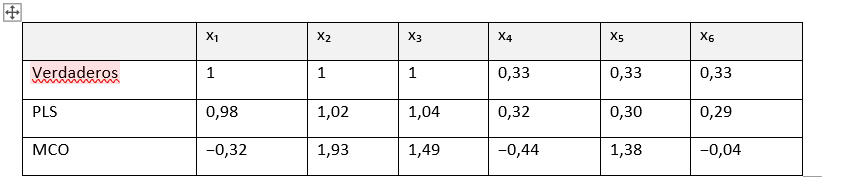

PLS reparte el mérito de forma equitativa y razonable. MCO da un valor absurdo a cada variable, con signos negativos que no tienen sentido: es el síntoma exacto de la colinealidad.

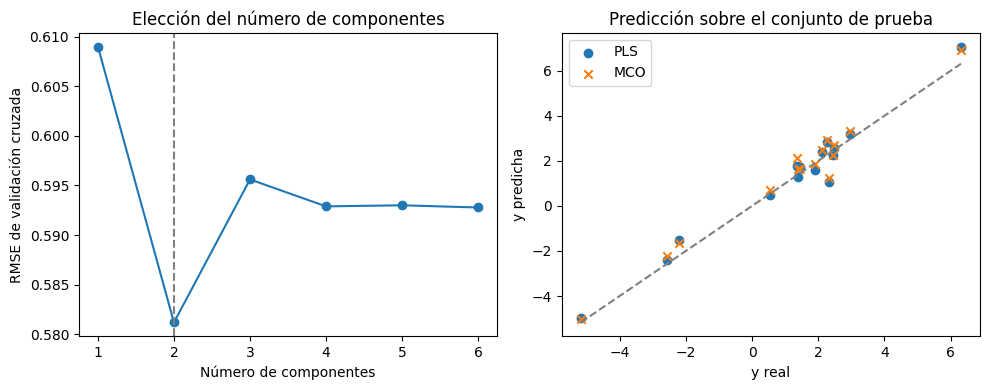

In [ ]:
# 7. GRÁFICOS
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].plot(range(1, max_comp + 1), rmse_cv, marker="o")
ax[0].axvline(best_a, linestyle="--", color="gray")
ax[0].set_xlabel("Número de componentes")
ax[0].set_ylabel("RMSE de validación cruzada")
ax[0].set_title("Elección del número de componentes")

ax[1].scatter(y_te, y_pred_pls, label="PLS")
ax[1].scatter(y_te, y_pred_ols, marker="x", label="MCO")
lims = [y_te.min(), y_te.max()]
ax[1].plot(lims, lims, color="gray", linestyle="--")   # la diagonal es la predicción perfecta
ax[1].set_xlabel("y real")
ax[1].set_ylabel("y predicha")
ax[1].set_title("Predicción sobre el conjunto de prueba")
ax[1].legend()

plt.tight_layout()
plt.savefig("ejemplo_pls.png", dpi=150)
plt.show()


# 5. Conclusión

Mientras que la regresión tradicional falla y da resultados absurdos cuando los datos están repetidos o conectados entre sí, PLS es la única herramienta capaz de neutralizar esa redundancia; limpia el ruido y reparte el peso de las variables de forma lógica y estable, garantizando predicciones totalmente confiables.s
